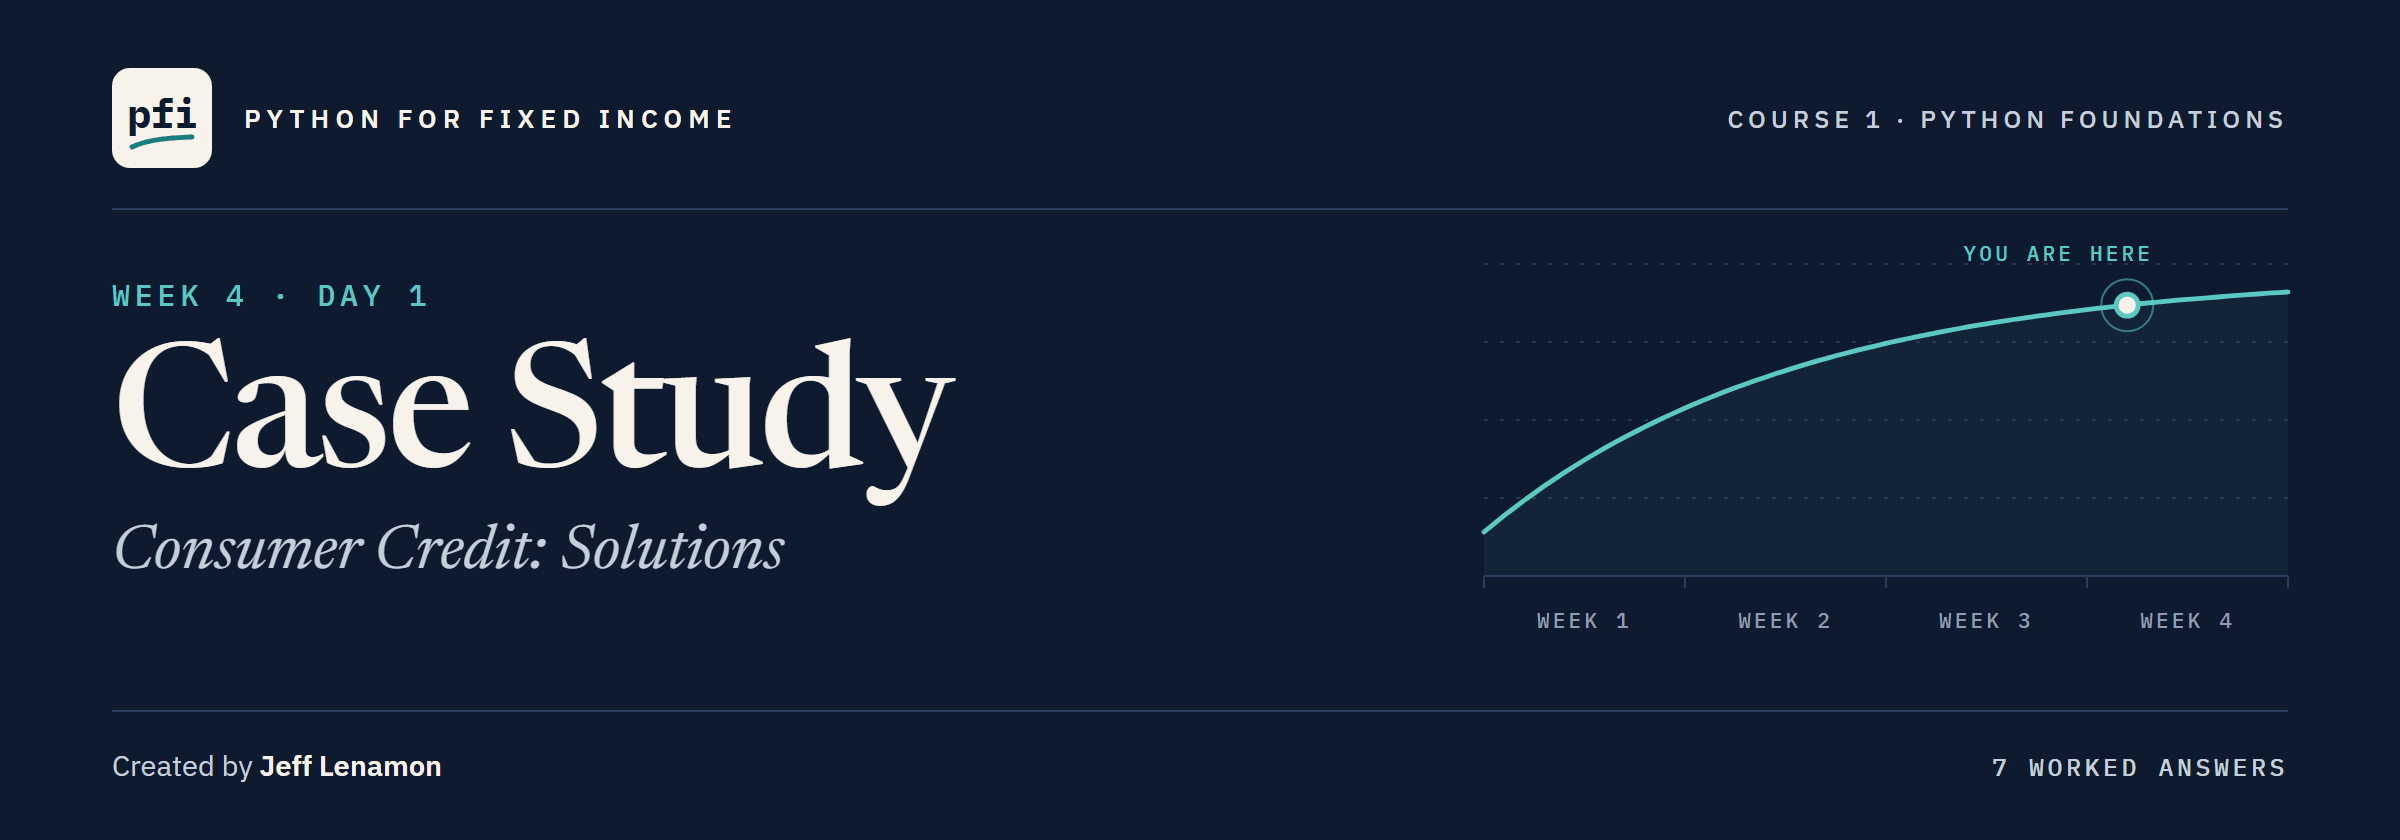

# Case Study: Consumer Credit: Solutions

Week 4, Day 1. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day1/16_case_study_consumer_credit_solutions.ipynb)

## Exercises

Worked answers on the UCI "Default of Credit Card Clients" file by I-Cheng Yeh (CC BY 4.0), as set out in the teaching notebook.
Each answer is followed by the check cell from the teaching notebook.
Run the next two cells first: the first defines `check`, the second loads `cards`.

In [1]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [2]:
import os

import numpy as np
import pandas as pd

if os.path.exists('../../../data/credit_card_default.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
raw = pd.read_csv(data_folder + 'credit_card_default.csv')
cards = raw.rename(columns={'default payment next month': 'default'})
cards['sex'] = cards['SEX'].map({1: 'male', 2: 'female'})
cards['education'] = cards['EDUCATION'].map({1: 'graduate school', 2: 'university',
                                             3: 'high school', 4: 'others'})
cards['education'] = cards['education'].fillna('not documented')
cards['marriage'] = cards['MARRIAGE'].map({1: 'married', 2: 'single', 3: 'others'})
cards['marriage'] = cards['marriage'].fillna('not documented')
pay_columns = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
print(cards.shape)

(30000, 28)


### Exercise 1

Q. Count the accounts with a `PAY_2`, August's status, of 2, and find their rate in percent to 2 decimals: **ex1_accounts**, **ex1_rate**.

In [3]:
# accounts, defaults, and rate for each August code
by_august = cards.groupby('PAY_2')['default'].agg(['count', 'sum', 'mean'])
by_august['mean'] = (by_august['mean'] * 100).round(2)
print(by_august)

ex1_accounts = by_august.loc[2, 'count']
ex1_rate = by_august.loc[2, 'mean']
print('August status 2:', ex1_accounts, 'accounts,', ex1_rate, 'percent')

       count   sum   mean
PAY_2                    
-2      3782   691  18.27
-1      6050   966  15.97
 0     15730  2503  15.91
 1        28     5  17.86
 2      3927  2184  55.61
 3       326   201  61.66
 4        99    50  50.51
 5        25    15  60.00
 6        12     9  75.00
 7        20    12  60.00
 8         1     0   0.00
August status 2: 3927 accounts, 55.61 percent


3,927 accounts held an August status of 2, and 55.61 percent of them defaulted; September's code 2 was 69.14 percent on 2,667.
In August the undocumented 0 holds the lowest rate, 15.91 percent, and code 1 sits on only 28 accounts.

In [4]:
check('Exercise 1 accounts', ex1_accounts, 3927)
check('Exercise 1 rate', ex1_rate, 55.61)

Exercise 1 accounts: correct
Exercise 1 rate: correct


### Exercise 2

Q. Find the median credit limit for `graduate school` and for `high school`: **ex2_graduate**, **ex2_high_school**.

In [5]:
# the accounts and the median limit for each education label
limit_by_education = cards.groupby('education')['LIMIT_BAL'].agg(['count', 'median'])
print(limit_by_education)

ex2_graduate = limit_by_education.loc['graduate school', 'median']
ex2_high_school = limit_by_education.loc['high school', 'median']

                 count    median
education                       
graduate school  10585  200000.0
high school       4917   80000.0
not documented     345  150000.0
others             123  200000.0
university       14030  110000.0


A median limit of 200,000 NT dollars for graduate school and 80,000 for high school.
Education and limit move together, so the lesson's findings on the two are not independent: a reason for care, not an explanation.

In [6]:
check('Exercise 2 graduate school', ex2_graduate, 200000.0)
check('Exercise 2 high school', ex2_high_school, 80000.0)

Exercise 2 graduate school: correct
Exercise 2 high school: correct


### Exercise 3

Q. Pivot the rate and the count, `marriage` down and `sex` across; for `married` and `male`, the rate in percent to 2 decimals and the count: **ex3_rate**, **ex3_accounts**.

In [7]:
# the rate of each combination in percent, then the count of each
rates = pd.pivot_table(cards, values='default', index='marriage', columns='sex', aggfunc='mean')
rates = (rates * 100).round(2)
counts = pd.pivot_table(cards, values='default', index='marriage', columns='sex', aggfunc='count')
print(rates)
print(counts)

ex3_rate = rates.loc['married', 'male']
ex3_accounts = counts.loc['married', 'male']

sex             female   male
marriage                     
married          21.96  25.93
not documented    7.50  14.29
others           22.92  30.53
single           19.72  22.66
sex             female  male
marriage                    
married           8469  5190
not documented      40    14
others             192   131
single            9411  6553


25.93 percent of the 5,190 accounts labelled married and male defaulted.
The thinnest cell, `not documented` and male, holds 14 accounts: read its rate with that count.

In [8]:
check('Exercise 3 rate', ex3_rate, 25.93)
check('Exercise 3 accounts', ex3_accounts, 5190)

Exercise 3 rate: correct
Exercise 3 accounts: correct


### Exercise 4

Q. Count each account's months with a zero payment (`PAY_AMT1` to `PAY_AMT6`); then the accounts with six, and their rate in percent to 2 decimals: **ex4_accounts**, **ex4_rate**.

In [9]:
payment_columns = ['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
# True for each month with a payment of zero, added across the row
cards['months_unpaid'] = (cards[payment_columns] == 0).sum(axis=1)
by_unpaid = cards.groupby('months_unpaid')['default'].agg(['count', 'mean'])
by_unpaid['mean'] = (by_unpaid['mean'] * 100).round(2)
print(by_unpaid)

ex4_accounts = by_unpaid.loc[6, 'count']
ex4_rate = by_unpaid.loc[6, 'mean']

               count   mean
months_unpaid              
0              15458  13.92
1               5473  28.98
2               3387  33.69
3               1944  31.28
4               1304  25.15
5               1002  27.74
6               1432  37.99


1,432 accounts paid nothing in all six months, and 37.99 percent defaulted; of those that paid every month, 13.92 percent did.
The rates do not climb step by step in between, and a zero payment on a zero bill is not a missed payment: the page does not say which is which.

In [10]:
check('Exercise 4 accounts', ex4_accounts, 1432)
check('Exercise 4 rate', ex4_rate, 37.99)

Exercise 4 accounts: correct
Exercise 4 rate: correct


### Exercise 5

Q. Write `margin_of_error(defaults, accounts)`, returning 1.96 x sqrt(p x (1 - p) / n) x 100 to 2 decimals, `p` the defaults over the accounts.

In [11]:
def margin_of_error(defaults, accounts):
    """Return the rough margin of error of a default rate, in percentage points, to 2 decimals."""
    # the rate as a fraction
    p = defaults / accounts
    return round(1.96 * np.sqrt(p * (1 - p) / accounts) * 100, 2)


for defaults, accounts in [(7, 123), (6636, 30000), (2, 14)]:
    print(defaults, 'in', accounts, ':', round(defaults / accounts * 100, 2),
          'percent, give or take', margin_of_error(defaults, accounts), 'points')

7 in 123 : 5.69 percent, give or take 4.09 points
6636 in 30000 : 22.12 percent, give or take 0.47 points
2 in 14 : 14.29 percent, give or take 18.33 points


2 in 14 is 14.29 percent, give or take 18.33 points: a margin larger than the rate says 14 accounts cannot pin a rate down.
The function returns its answer, so the check cell can call it with any two numbers.

In [12]:
check('Exercise 5 others, 7 in 123', margin_of_error(7, 123), 4.09)
check('Exercise 5 whole file', margin_of_error(6636, 30000), 0.47)
check('Exercise 5 thin cell, 2 in 14', margin_of_error(2, 14), 18.33)

Exercise 5 others, 7 in 123: correct
Exercise 5 whole file: correct
Exercise 5 thin cell, 2 in 14: correct


### Exercise 6

Q. Count the accounts above the upper IQR fence of August's payment, `PAY_AMT2`, and find their rate in percent to 2 decimals: **ex6_accounts**, **ex6_rate**.

In [13]:
q1 = cards['PAY_AMT2'].quantile(0.25)
q3 = cards['PAY_AMT2'].quantile(0.75)
upper_fence = q3 + 1.5 * (q3 - q1)
above = cards['PAY_AMT2'] > upper_fence

ex6_accounts = above.sum()
ex6_rate = round(cards.loc[above, 'default'].mean() * 100, 2)
print('Fence:', upper_fence, '| above:', ex6_accounts, '| rate:', ex6_rate,
      '| the rest:', round(cards.loc[~above, 'default'].mean() * 100, 2))

Fence: 11250.5 | above: 2714 | rate: 10.43 | the rest: 23.28


2,714 accounts paid more than the fence of 11,250.5 NT dollars in August, and 10.43 percent defaulted, against 23.28 for the rest.
As in the lesson, far from the middle is a distance, not a reason to drop a row.

In [14]:
check('Exercise 6 accounts', ex6_accounts, 2714)
check('Exercise 6 rate', ex6_rate, 10.43)

Exercise 6 accounts: correct
Exercise 6 rate: correct


### Exercise 7: AI check

Q. What count and overall rate do you expect, from 16.2? Run the code. Does it agree?

The file has 30,000 accounts and a rate of 22.12 percent; the original printed 29,655 and 22.29, with no warning.
`isin([1, 2, 3, 4])`, called clean-up, dropped the 345 accounts with codes 0, 5, and 6; their 26 defaults in 345, 7.54 percent, were holding the overall rate down.
The four rates it printed were right: the table misled by what it left out.

In [15]:
# every account kept, the undocumented codes as a group of their own
by_level = cards.groupby('education')['default'].agg(['count', 'mean'])
by_level['mean'] = (by_level['mean'] * 100).round(2)
print(by_level)

ex7_accounts = by_level['count'].sum()
ex7_overall_rate = round(cards['default'].mean() * 100, 2)
print('Accounts in the table:', ex7_accounts)
print('Overall default rate:', ex7_overall_rate, 'percent')

                 count   mean
education                    
graduate school  10585  19.23
high school       4917  25.16
not documented     345   7.54
others             123   5.69
university       14030  23.73
Accounts in the table: 30000
Overall default rate: 22.12 percent


In [16]:
check('Exercise 7 accounts', ex7_accounts, 30000)
check('Exercise 7 overall rate', ex7_overall_rate, 22.12)

Exercise 7 accounts: correct
Exercise 7 overall rate: correct


[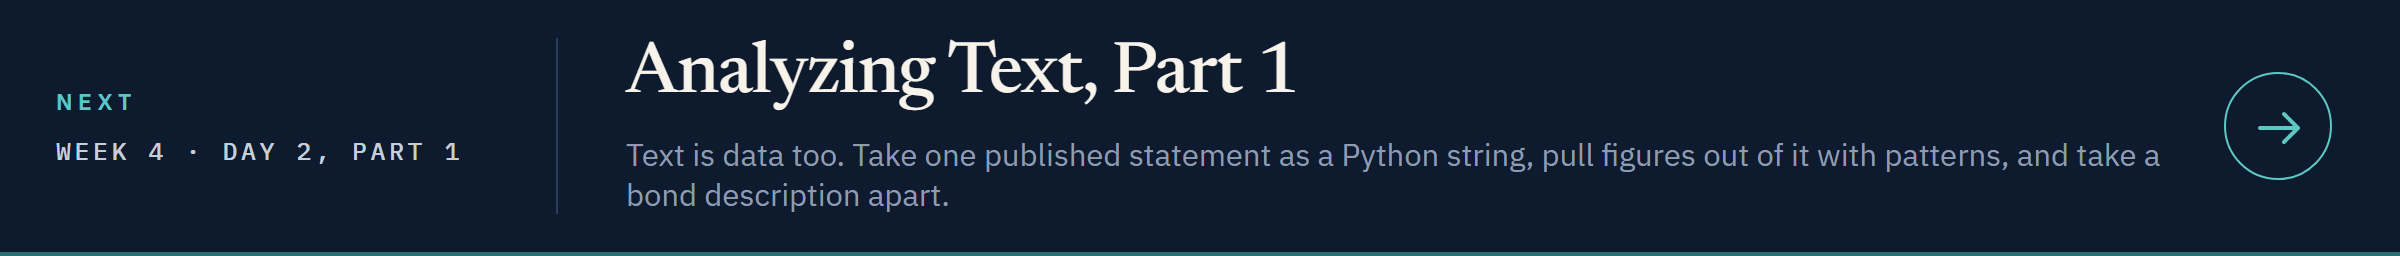](../day2/17_analyzing_text.ipynb)

[Open Day 2, Part 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day2/17_analyzing_text.ipynb)